In [1]:
import os
import random
import time
import copy

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Device: cpu


In [2]:
# CIFAR-10 preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

batch_size = 100

trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

trainloader = DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

testloader = DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

print("Training images:", len(trainset))
print("Test images:", len(testset))
print("Number of classes:", len(classes))

Training images: 50000
Test images: 10000
Number of classes: 10


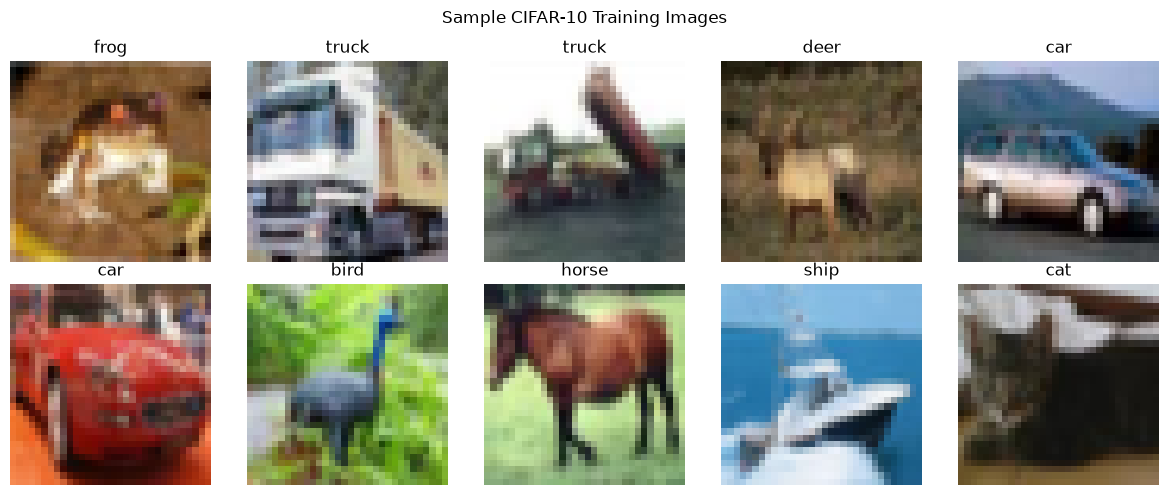

In [3]:
def show_cifar_samples(dataset, classes, count=10):
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))

    for i, ax in enumerate(axes.flat):
        image, label = dataset[i]

        # Undo normalization for display
        image = image * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()

        ax.imshow(np.clip(image, 0, 1))
        ax.set_title(classes[label])
        ax.axis("off")

    plt.suptitle("Sample CIFAR-10 Training Images")
    plt.tight_layout()
    plt.show()

show_cifar_samples(trainset, classes)

In [4]:
Din = 3 * 32 * 32
H = 100
K = 10

# Hyperparameters
epochs = 10
learning_rate = 0.01
learning_rate_decay = 0.95

# Xavier-style initialization for sigmoid hidden units
W1 = torch.randn(Din, H, device=device) * np.sqrt(1.0 / Din)
b1 = torch.zeros(H, device=device)

W2 = torch.randn(H, K, device=device) * np.sqrt(1.0 / H)
b2 = torch.zeros(K, device=device)

print("W1:", tuple(W1.shape))
print("b1:", tuple(b1.shape))
print("W2:", tuple(W2.shape))
print("b2:", tuple(b2.shape))

W1: (3072, 100)
b1: (100,)
W2: (100, 10)
b2: (10,)


In [5]:
def forward_pass(X, W1, b1, W2, b2):
    # Hidden layer
    Z1 = X @ W1 + b1
    H = torch.sigmoid(Z1)

    # Output layer: raw class scores (logits)
    Z2 = H @ W2 + b2

    return Z1, H, Z2


def cross_entropy_loss(logits, labels):
    # Stable softmax cross-entropy
    log_probs = F.log_softmax(logits, dim=1)

    # Select the correct class log-probability
    correct_log_probs = log_probs[
        torch.arange(labels.shape[0], device=labels.device),
        labels
    ]

    return -correct_log_probs.mean()

In [6]:
def manual_backprop(X, labels, W1, b1, W2, b2):
    N = X.shape[0]

    # Forward pass
    Z1, H, logits = forward_pass(X, W1, b1, W2, b2)

    loss = cross_entropy_loss(logits, labels)

    # Softmax probabilities
    probs = F.softmax(logits, dim=1)

    # Gradient of cross-entropy with respect to logits
    dZ2 = probs.clone()
    dZ2[
        torch.arange(N, device=labels.device), labels
    ] -= 1.0
    dZ2 /= N

    # Output layer gradients
    dW2 = H.T @ dZ2
    db2 = dZ2.sum(dim=0)

    # Backpropagate through the hidden layer
    dH = dZ2 @ W2.T

    # Derivative of sigmoid
    dZ1 = dH * H * (1.0 - H)

    # Hidden layer gradients
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(dim=0)

    gradients = (dW1, db1, dW2, db2)

    return loss, gradients, logits

In [7]:
task1_history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": []
}


def evaluate_manual_network(loader):
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            X = images.reshape(images.shape[0], -1)

            _, _, logits = forward_pass(
                X, W1, b1, W2, b2
            )

            loss = cross_entropy_loss(logits, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100.0 * correct / total


lr = learning_rate

start_time = time.time()

for epoch in range(epochs):
    running_loss = 0.0
    total_seen = 0

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        X = images.reshape(images.shape[0], -1)

        # Manually calculate gradients
        loss, grads, logits = manual_backprop(
            X, labels, W1, b1, W2, b2
        )

        dW1, db1, dW2, db2 = grads

        # Manual gradient-descent parameter updates
        with torch.no_grad():
            W1 -= lr * dW1
            b1 -= lr * db1
            W2 -= lr * dW2
            b2 -= lr * db2

        running_loss += loss.item() * labels.size(0)
        total_seen += labels.size(0)

    # Evaluate after each epoch
    train_loss, train_acc = evaluate_manual_network(trainloader)
    test_loss, test_acc = evaluate_manual_network(testloader)

    task1_history["train_loss"].append(train_loss)
    task1_history["train_accuracy"].append(train_acc)
    task1_history["test_loss"].append(test_loss)
    task1_history["test_accuracy"].append(test_acc)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_acc:.2f}%"
    )

    lr *= learning_rate_decay

print(f"\nTotal training time: {(time.time() - start_time) / 60:.2f} minutes")

Epoch 01/10 | Train Loss: 1.9754 | Train Accuracy: 32.98% | Test Loss: 1.9735 | Test Accuracy: 33.04%
Epoch 02/10 | Train Loss: 1.8947 | Train Accuracy: 35.52% | Test Loss: 1.8946 | Test Accuracy: 35.24%
Epoch 03/10 | Train Loss: 1.8539 | Train Accuracy: 36.35% | Test Loss: 1.8549 | Test Accuracy: 35.88%
Epoch 04/10 | Train Loss: 1.8266 | Train Accuracy: 37.41% | Test Loss: 1.8285 | Test Accuracy: 36.79%
Epoch 05/10 | Train Loss: 1.8070 | Train Accuracy: 38.13% | Test Loss: 1.8093 | Test Accuracy: 37.64%
Epoch 06/10 | Train Loss: 1.7918 | Train Accuracy: 38.51% | Test Loss: 1.7953 | Test Accuracy: 38.20%
Epoch 07/10 | Train Loss: 1.7791 | Train Accuracy: 38.83% | Test Loss: 1.7827 | Test Accuracy: 38.66%
Epoch 08/10 | Train Loss: 1.7687 | Train Accuracy: 39.24% | Test Loss: 1.7727 | Test Accuracy: 39.25%
Epoch 09/10 | Train Loss: 1.7601 | Train Accuracy: 39.53% | Test Loss: 1.7643 | Test Accuracy: 39.18%
Epoch 10/10 | Train Loss: 1.7519 | Train Accuracy: 39.71% | Test Loss: 1.7566 | Te

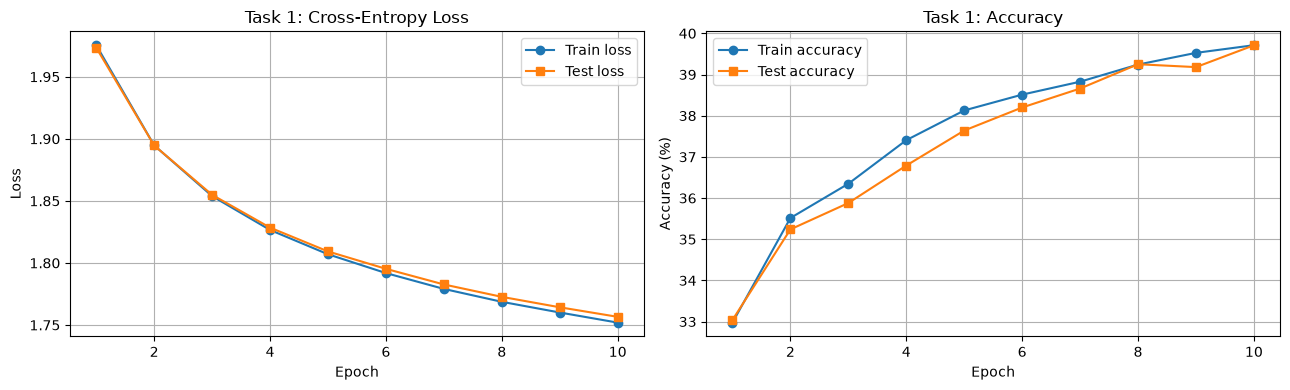

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

epochs_axis = range(1, epochs + 1)

axes[0].plot(
    epochs_axis, task1_history["train_loss"],
    marker="o", label="Train loss"
)
axes[0].plot(
    epochs_axis, task1_history["test_loss"],
    marker="s", label="Test loss"
)
axes[0].set_title("Task 1: Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs_axis, task1_history["train_accuracy"],
    marker="o", label="Train accuracy"
)
axes[1].plot(
    epochs_axis, task1_history["test_accuracy"],
    marker="s", label="Test accuracy"
)
axes[1].set_title("Task 1: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [9]:
task1_results = pd.DataFrame({
    "Metric": ["Training accuracy", "Test accuracy"],
    "Value (%)": [
        task1_history["train_accuracy"][-1],
        task1_history["test_accuracy"][-1]
    ]
})

display(task1_results)

,Metric,Value (%)
0,Training accuracy,39.712
1,Test accuracy,39.710


In [10]:
# Task 2(a) - Cell 1: Load MNIST

batch_size_mnist = 128

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

trainset_mnist = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=mnist_transform
)

testset_mnist = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=mnist_transform
)

trainloader_mnist = DataLoader(
    trainset_mnist,
    batch_size=batch_size_mnist,
    shuffle=True,
    num_workers=0
)

testloader_mnist = DataLoader(
    testset_mnist,
    batch_size=batch_size_mnist,
    shuffle=False,
    num_workers=0
)

print("MNIST training images:", len(trainset_mnist))
print("MNIST test images:", len(testset_mnist))
print("Number of classes:", 10)
print("Image shape:", trainset_mnist[0][0].shape)


MNIST training images: 60000
MNIST test images: 10000
Number of classes: 10
Image shape: torch.Size([1, 28, 28])


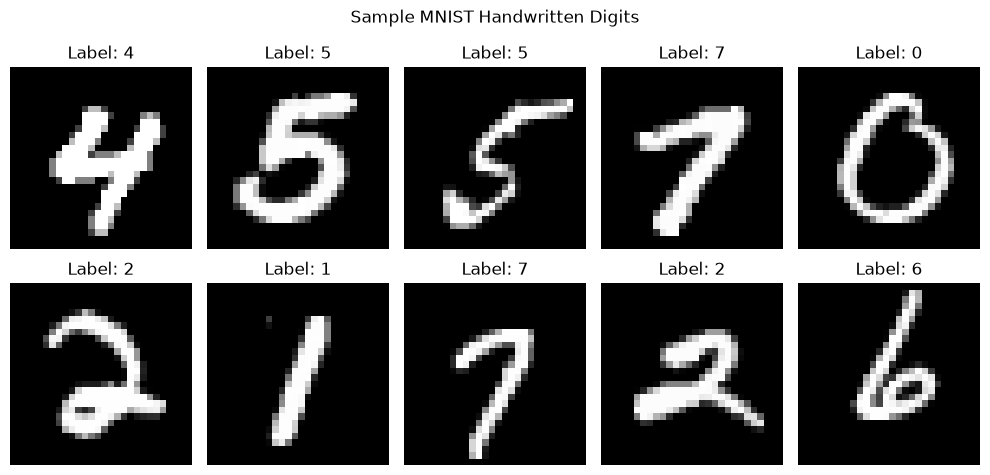

In [11]:
digit_names = [str(i) for i in range(10)]

images, labels = next(iter(trainloader_mnist))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    # Undo normalization for display
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.suptitle("Sample MNIST Handwritten Digits")
plt.tight_layout()
plt.show()


In [12]:
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = self.pool1(x)

        x = torch.tanh(self.conv2(x))
        x = self.pool2(x)

        x = torch.flatten(x, start_dim=1)

        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)

        return x


lenet_model = LeNet5().to(device)

criterion_lenet = nn.CrossEntropyLoss()
optimizer_lenet = optim.Adam(
    lenet_model.parameters(),
    lr=0.001
)

print(lenet_model)
print("Device:", device)


LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=256, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Device: cpu


In [13]:
epochs_lenet = 10

task2a_history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": []
}


def evaluate_lenet(loader):
    lenet_model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = lenet_model(images)
            loss = criterion_lenet(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy


start_time_lenet = time.time()

for epoch in range(epochs_lenet):
    lenet_model.train()

    running_loss = 0.0
    total_seen = 0

    for images, labels in trainloader_mnist:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_lenet.zero_grad()

        outputs = lenet_model(images)
        loss = criterion_lenet(outputs, labels)

        loss.backward()
        optimizer_lenet.step()

        running_loss += loss.item() * labels.size(0)
        total_seen += labels.size(0)

    train_loss, train_acc = evaluate_lenet(trainloader_mnist)
    test_loss, test_acc = evaluate_lenet(testloader_mnist)

    task2a_history["train_loss"].append(train_loss)
    task2a_history["train_accuracy"].append(train_acc)
    task2a_history["test_loss"].append(test_loss)
    task2a_history["test_accuracy"].append(test_acc)

    print(
        f"Epoch {epoch + 1:02d}/{epochs_lenet} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_acc:.2f}%"
    )

print(
    f"\nTraining time: "
    f"{(time.time() - start_time_lenet) / 60:.2f} minutes"
)


Epoch 01/10 | Train Loss: 0.1000 | Train Accuracy: 97.04% | Test Loss: 0.0956 | Test Accuracy: 97.13%
Epoch 02/10 | Train Loss: 0.0626 | Train Accuracy: 98.09% | Test Loss: 0.0612 | Test Accuracy: 97.93%
Epoch 03/10 | Train Loss: 0.0440 | Train Accuracy: 98.67% | Test Loss: 0.0474 | Test Accuracy: 98.49%
Epoch 04/10 | Train Loss: 0.0320 | Train Accuracy: 99.07% | Test Loss: 0.0371 | Test Accuracy: 98.77%
Epoch 05/10 | Train Loss: 0.0275 | Train Accuracy: 99.18% | Test Loss: 0.0361 | Test Accuracy: 98.87%
Epoch 06/10 | Train Loss: 0.0232 | Train Accuracy: 99.30% | Test Loss: 0.0341 | Test Accuracy: 98.98%
Epoch 07/10 | Train Loss: 0.0200 | Train Accuracy: 99.40% | Test Loss: 0.0367 | Test Accuracy: 98.86%
Epoch 08/10 | Train Loss: 0.0170 | Train Accuracy: 99.48% | Test Loss: 0.0336 | Test Accuracy: 98.90%
Epoch 09/10 | Train Loss: 0.0139 | Train Accuracy: 99.57% | Test Loss: 0.0334 | Test Accuracy: 98.92%
Epoch 10/10 | Train Loss: 0.0184 | Train Accuracy: 99.40% | Test Loss: 0.0412 | Te

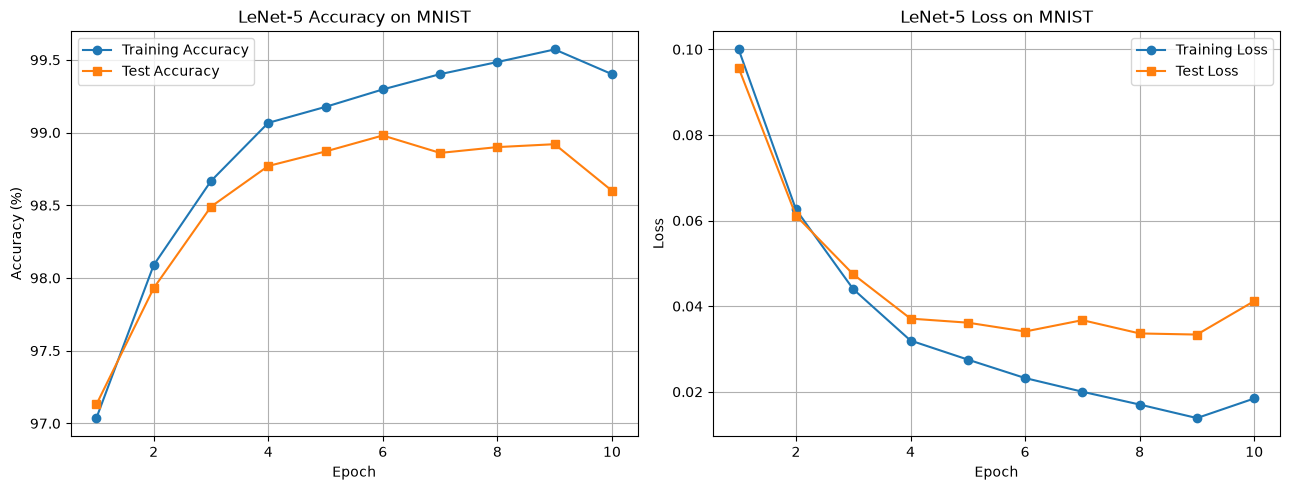

In [14]:
epoch_numbers = range(1, epochs_lenet + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    epoch_numbers,
    task2a_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[0].plot(
    epoch_numbers,
    task2a_history["test_accuracy"],
    marker="s",
    label="Test Accuracy"
)
axes[0].set_title("LeNet-5 Accuracy on MNIST")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epoch_numbers,
    task2a_history["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[1].plot(
    epoch_numbers,
    task2a_history["test_loss"],
    marker="s",
    label="Test Loss"
)
axes[1].set_title("LeNet-5 Loss on MNIST")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [15]:
lenet_results = pd.DataFrame({
    "Metric": ["Training Accuracy", "Test Accuracy"],
    "Value (%)": [
        task2a_history["train_accuracy"][-1],
        task2a_history["test_accuracy"][-1]
    ]
})

display(lenet_results)

os.makedirs("results", exist_ok=True)

pd.DataFrame(task2a_history).to_csv(
    "results/task2a_lenet_history.csv",
    index=False
)

torch.save(
    lenet_model.state_dict(),
    "results/task2a_lenet5_mnist.pth"
)

print("LeNet-5 history and model saved.")


,Metric,Value (%)
0,Training Accuracy,99.401667
1,Test Accuracy,98.600000


LeNet-5 history and model saved.


In [16]:
class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()

        # Convolutional layer 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # Convolutional layer 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Convolutional layer 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout_conv = nn.Dropout2d(0.25)
        self.dropout_fc = nn.Dropout(0.5)

        # 28x28 -> 14x14 -> 7x7 -> 3x3
        self.fc1 = nn.Linear(128 * 3 * 3, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = self.dropout_conv(x)
        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.dropout_fc(x)
        x = self.fc2(x)

        return x


modern_model = ModernCNN().to(device)

criterion_modern = nn.CrossEntropyLoss()
optimizer_modern = optim.Adam(
    modern_model.parameters(),
    lr=0.001
)

print(modern_model)
print("Device:", device)


ModernCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout_conv): Dropout2d(p=0.25, inplace=False)
  (dropout_fc): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=1152, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Device: cpu


In [17]:
epochs_modern = 10

task2b_history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": []
}


def evaluate_modern(loader):
    modern_model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = modern_model(images)
            loss = criterion_modern(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100.0 * correct / total


start_time_modern = time.time()

for epoch in range(epochs_modern):
    modern_model.train()

    for images, labels in trainloader_mnist:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_modern.zero_grad()

        outputs = modern_model(images)
        loss = criterion_modern(outputs, labels)

        loss.backward()
        optimizer_modern.step()

    train_loss, train_acc = evaluate_modern(trainloader_mnist)
    test_loss, test_acc = evaluate_modern(testloader_mnist)

    task2b_history["train_loss"].append(train_loss)
    task2b_history["train_accuracy"].append(train_acc)
    task2b_history["test_loss"].append(test_loss)
    task2b_history["test_accuracy"].append(test_acc)

    print(
        f"Epoch {epoch + 1:02d}/{epochs_modern} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_acc:.2f}%"
    )

print(
    f"\nTraining time: "
    f"{(time.time() - start_time_modern) / 60:.2f} minutes"
)


Epoch 01/10 | Train Loss: 0.0438 | Train Accuracy: 98.59% | Test Loss: 0.0399 | Test Accuracy: 98.62%
Epoch 02/10 | Train Loss: 0.0268 | Train Accuracy: 99.14% | Test Loss: 0.0278 | Test Accuracy: 99.15%
Epoch 03/10 | Train Loss: 0.0240 | Train Accuracy: 99.23% | Test Loss: 0.0270 | Test Accuracy: 99.02%
Epoch 04/10 | Train Loss: 0.0176 | Train Accuracy: 99.45% | Test Loss: 0.0221 | Test Accuracy: 99.25%
Epoch 05/10 | Train Loss: 0.0131 | Train Accuracy: 99.60% | Test Loss: 0.0247 | Test Accuracy: 99.18%
Epoch 06/10 | Train Loss: 0.0176 | Train Accuracy: 99.39% | Test Loss: 0.0289 | Test Accuracy: 99.08%
Epoch 07/10 | Train Loss: 0.0125 | Train Accuracy: 99.61% | Test Loss: 0.0236 | Test Accuracy: 99.23%
Epoch 08/10 | Train Loss: 0.0087 | Train Accuracy: 99.74% | Test Loss: 0.0198 | Test Accuracy: 99.34%
Epoch 09/10 | Train Loss: 0.0067 | Train Accuracy: 99.80% | Test Loss: 0.0189 | Test Accuracy: 99.37%
Epoch 10/10 | Train Loss: 0.0108 | Train Accuracy: 99.65% | Test Loss: 0.0272 | Te

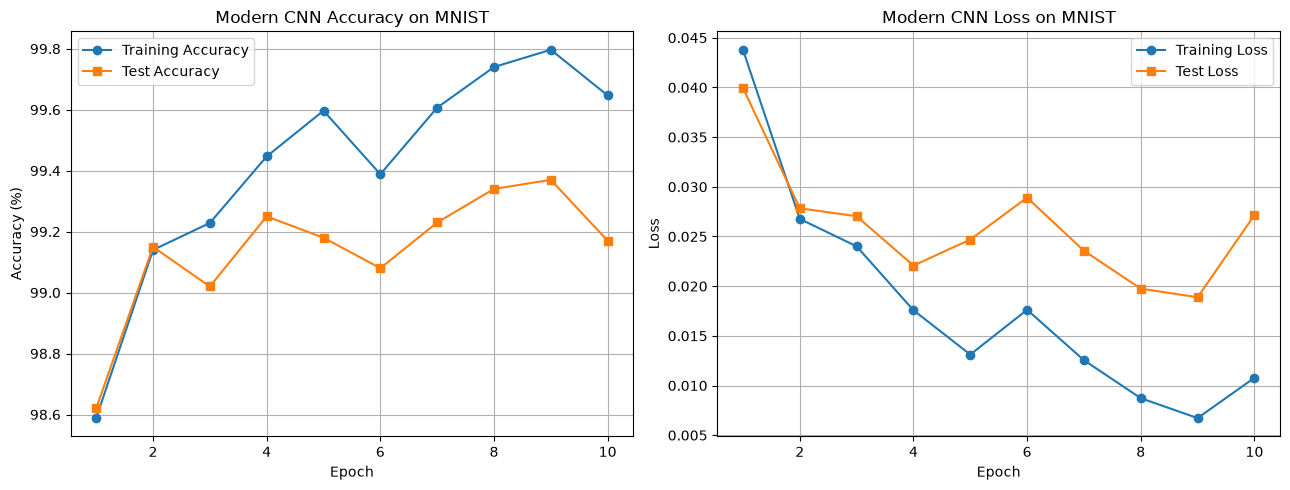

In [18]:
epoch_numbers = range(1, epochs_modern + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    epoch_numbers,
    task2b_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[0].plot(
    epoch_numbers,
    task2b_history["test_accuracy"],
    marker="s",
    label="Test Accuracy"
)
axes[0].set_title("Modern CNN Accuracy on MNIST")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epoch_numbers,
    task2b_history["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[1].plot(
    epoch_numbers,
    task2b_history["test_loss"],
    marker="s",
    label="Test Loss"
)
axes[1].set_title("Modern CNN Loss on MNIST")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [19]:
modern_results = pd.DataFrame({
    "Metric": ["Training Accuracy", "Test Accuracy"],
    "Value (%)": [
        task2b_history["train_accuracy"][-1],
        task2b_history["test_accuracy"][-1]
    ]
})

display(modern_results)

os.makedirs("results", exist_ok=True)

pd.DataFrame(task2b_history).to_csv(
    "results/task2b_modern_cnn_history.csv",
    index=False
)

torch.save(
    modern_model.state_dict(),
    "results/task2b_modern_cnn_mnist.pth"
)

print("Modern CNN history and model saved.")


,Metric,Value (%)
0,Training Accuracy,99.646667
1,Test Accuracy,99.170000


Modern CNN history and model saved.


In [20]:
comparison_df = pd.DataFrame({
    "Model": ["LeNet-5", "Modern CNN"],
    "Training Accuracy (%)": [
        task2a_history["train_accuracy"][-1],
        task2b_history["train_accuracy"][-1]
    ],
    "Test Accuracy (%)": [
        task2a_history["test_accuracy"][-1],
        task2b_history["test_accuracy"][-1]
    ],
    "Training Loss": [
        task2a_history["train_loss"][-1],
        task2b_history["train_loss"][-1]
    ],
    "Test Loss": [
        task2a_history["test_loss"][-1],
        task2b_history["test_loss"][-1]
    ]
})

display(comparison_df.round(4))

print(
    "Test accuracy improvement:",
    f"{task2b_history['test_accuracy'][-1] - task2a_history['test_accuracy'][-1]:.2f}",
    "percentage points"
)

,Model,Training Accuracy (%),Test Accuracy (%),Training Loss,Test Loss
0,LeNet-5,99.4017,98.60,0.0184,0.0412
1,Modern CNN,99.6467,99.17,0.0108,0.0272


Test accuracy improvement: 0.57 percentage points


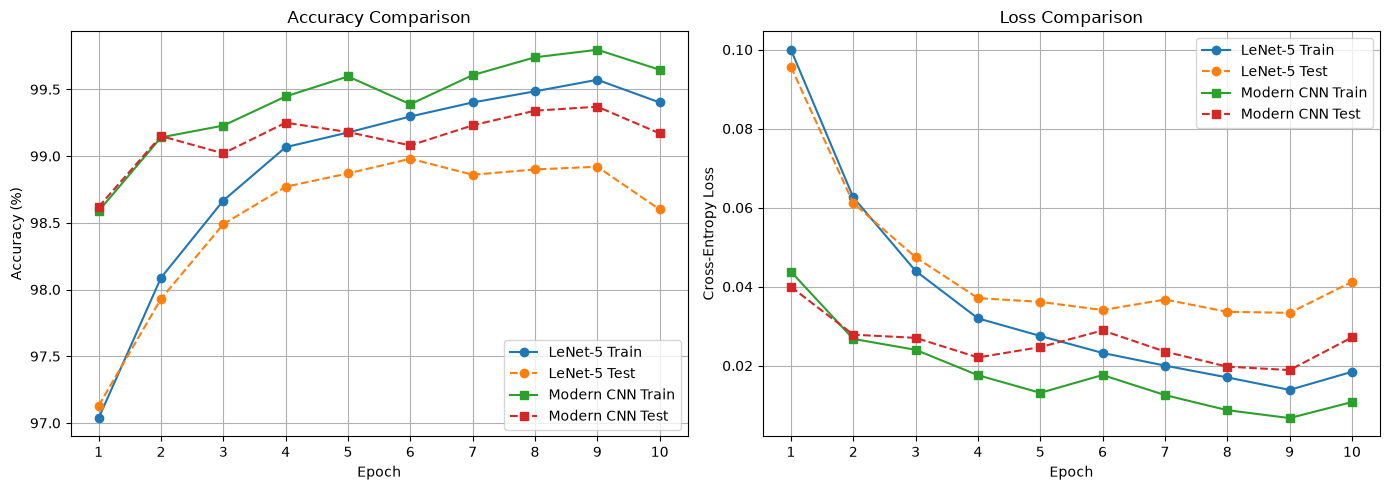

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, 11)

# Accuracy comparison
axes[0].plot(epochs_range, task2a_history["train_accuracy"],
             marker="o", label="LeNet-5 Train")
axes[0].plot(epochs_range, task2a_history["test_accuracy"],
             marker="o", linestyle="--", label="LeNet-5 Test")
axes[0].plot(epochs_range, task2b_history["train_accuracy"],
             marker="s", label="Modern CNN Train")
axes[0].plot(epochs_range, task2b_history["test_accuracy"],
             marker="s", linestyle="--", label="Modern CNN Test")

axes[0].set_title("Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_xticks(list(epochs_range))
axes[0].legend()
axes[0].grid(True)

# Loss comparison
axes[1].plot(epochs_range, task2a_history["train_loss"],
             marker="o", label="LeNet-5 Train")
axes[1].plot(epochs_range, task2a_history["test_loss"],
             marker="o", linestyle="--", label="LeNet-5 Test")
axes[1].plot(epochs_range, task2b_history["train_loss"],
             marker="s", label="Modern CNN Train")
axes[1].plot(epochs_range, task2b_history["test_loss"],
             marker="s", linestyle="--", label="Modern CNN Test")

axes[1].set_title("Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].set_xticks(list(epochs_range))
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

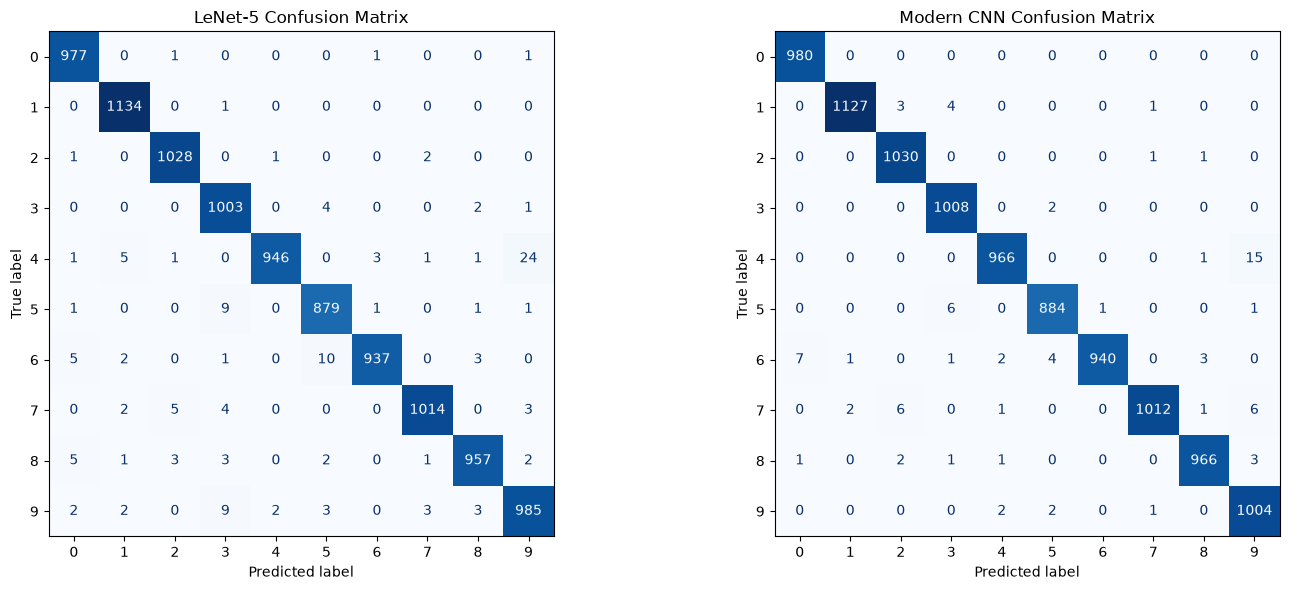

In [22]:
# Task 2(c) - Confusion matrices for both models

def get_predictions(model, loader):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_predictions)


# Obtain predictions on the test set
true_lenet, pred_lenet = get_predictions(
    lenet_model, testloader_mnist
)

true_modern, pred_modern = get_predictions(
    modern_model, testloader_mnist
)

# Calculate confusion matrices
cm_lenet = confusion_matrix(
    true_lenet, pred_lenet, labels=list(range(10))
)

cm_modern = confusion_matrix(
    true_modern, pred_modern, labels=list(range(10))
)

# Display both matrices
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_lenet,
    display_labels=list(range(10))
).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")

axes[0].set_title("LeNet-5 Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix=cm_modern,
    display_labels=list(range(10))
).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")

axes[1].set_title("Modern CNN Confusion Matrix")

plt.tight_layout()
plt.show()

In [23]:
os.makedirs("results", exist_ok=True)

comparison_df.to_csv(
    "results/task2c_model_comparison.csv",
    index=False
)

np.savetxt(
    "results/task2c_lenet_confusion_matrix.csv",
    cm_lenet,
    delimiter=",",
    fmt="%d"
)

np.savetxt(
    "results/task2c_modern_cnn_confusion_matrix.csv",
    cm_modern,
    delimiter=",",
    fmt="%d"
)

print("Task 2(c) results saved successfully.")

Task 2(c) results saved successfully.


In [24]:
import os
import urllib.request
import zipfile

data_dir = "./data"
dataset_dir = os.path.join(data_dir, "hymenoptera_data")
zip_path = os.path.join(data_dir, "hymenoptera_data.zip")

os.makedirs(data_dir, exist_ok=True)

if not os.path.exists(dataset_dir):
    url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
    print("Downloading Hymenoptera dataset...")
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(data_dir)

    print("Dataset extracted successfully!")
else:
    print("Hymenoptera dataset already exists.")

print("Dataset path:", dataset_dir)
print("Folders:", os.listdir(dataset_dir))

Hymenoptera dataset already exists.
Dataset path: ./data\hymenoptera_data
Folders: ['train', 'val']


In [26]:

import os
import copy
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

data_dir = "./data/hymenoptera_data"

data_transforms = {
    "train": transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),
    "val": transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),
}

image_datasets = {
    split: datasets.ImageFolder(
        os.path.join(data_dir, split),
        data_transforms[split]
    )
    for split in ["train", "val"]
}

dataloaders = {
    split: DataLoader(
        image_datasets[split],
        batch_size=16,
        shuffle=(split == "train"),
        num_workers=0
    )
    for split in ["train", "val"]
}

dataset_sizes = {
    split: len(image_datasets[split])
    for split in ["train", "val"]
}

class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Training images:", dataset_sizes["train"])
print("Validation images:", dataset_sizes["val"])


Device: cpu
Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


In [27]:
def train_model(model, criterion, optimizer, num_epochs=10):
    model = model.to(device)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_weights = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    start_time = time.time()

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch + 1}/{num_epochs}")

        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, predictions = torch.max(outputs, 1)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(
                    predictions == labels
                ).item()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_accuracy"].append(epoch_acc)

            print(
                f"{phase.title()} Loss: {epoch_loss:.4f} "
                f"Accuracy: {epoch_acc:.4f}"
            )

            if phase == "val" and epoch_acc > best_val_acc:
                best_val_acc = epoch_acc
                best_weights = copy.deepcopy(model.state_dict())

    elapsed = time.time() - start_time
    print(f"\nTraining completed in {elapsed / 60:.2f} minutes")
    print(f"Best validation accuracy: {best_val_acc:.4f}")

    model.load_state_dict(best_weights)
    return model, history


In [28]:
# Load pretrained ImageNet1K ResNet18
weights = models.ResNet18_Weights.DEFAULT
model_finetune = models.resnet18(weights=weights)

# Replace the classifier for ants and bees
num_features = model_finetune.fc.in_features
model_finetune.fc = nn.Linear(num_features, 2)

model_finetune = model_finetune.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_finetune = optim.SGD(
    model_finetune.parameters(),
    lr=0.001,
    momentum=0.9
)

model_finetune, history_finetune = train_model(
    model_finetune,
    criterion,
    optimizer_finetune,
    num_epochs=10
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\umain/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%



Epoch 1/10
Train Loss: 0.5291 Accuracy: 0.7418
Val Loss: 0.3088 Accuracy: 0.9150

Epoch 2/10
Train Loss: 0.2885 Accuracy: 0.8770
Val Loss: 0.2310 Accuracy: 0.9216

Epoch 3/10
Train Loss: 0.1863 Accuracy: 0.9344
Val Loss: 0.1962 Accuracy: 0.9346

Epoch 4/10
Train Loss: 0.1154 Accuracy: 0.9590
Val Loss: 0.1747 Accuracy: 0.9412

Epoch 5/10
Train Loss: 0.1104 Accuracy: 0.9590
Val Loss: 0.1925 Accuracy: 0.9216

Epoch 6/10
Train Loss: 0.0523 Accuracy: 0.9877
Val Loss: 0.1680 Accuracy: 0.9477

Epoch 7/10
Train Loss: 0.0350 Accuracy: 0.9959
Val Loss: 0.2450 Accuracy: 0.8824

Epoch 8/10
Train Loss: 0.0296 Accuracy: 1.0000
Val Loss: 0.1705 Accuracy: 0.9412

Epoch 9/10
Train Loss: 0.0368 Accuracy: 0.9959
Val Loss: 0.2527 Accuracy: 0.8954

Epoch 10/10
Train Loss: 0.0247 Accuracy: 0.9959
Val Loss: 0.2169 Accuracy: 0.9085

Training completed in 9.07 minutes
Best validation accuracy: 0.9477


In [29]:
model_feature = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze all pretrained parameters
for parameter in model_feature.parameters():
    parameter.requires_grad = False

# Replace the final layer; it remains trainable
num_features = model_feature.fc.in_features
model_feature.fc = nn.Linear(num_features, 2)

model_feature = model_feature.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_feature = optim.SGD(
    model_feature.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

model_feature, history_feature = train_model(
    model_feature,
    criterion,
    optimizer_feature,
    num_epochs=10
)



Epoch 1/10
Train Loss: 0.6621 Accuracy: 0.6189
Val Loss: 0.4300 Accuracy: 0.8562

Epoch 2/10
Train Loss: 0.3814 Accuracy: 0.8484
Val Loss: 0.2930 Accuracy: 0.9020

Epoch 3/10
Train Loss: 0.3668 Accuracy: 0.8443
Val Loss: 0.3920 Accuracy: 0.8039

Epoch 4/10
Train Loss: 0.2722 Accuracy: 0.8934
Val Loss: 0.2197 Accuracy: 0.9281

Epoch 5/10
Train Loss: 0.1844 Accuracy: 0.9385
Val Loss: 0.2437 Accuracy: 0.9020

Epoch 6/10
Train Loss: 0.2191 Accuracy: 0.9385
Val Loss: 0.2030 Accuracy: 0.9412

Epoch 7/10
Train Loss: 0.1903 Accuracy: 0.9303
Val Loss: 0.2039 Accuracy: 0.9216

Epoch 8/10
Train Loss: 0.1793 Accuracy: 0.9385
Val Loss: 0.2087 Accuracy: 0.9216

Epoch 9/10
Train Loss: 0.1287 Accuracy: 0.9631
Val Loss: 0.1981 Accuracy: 0.9281

Epoch 10/10
Train Loss: 0.1785 Accuracy: 0.9426
Val Loss: 0.1942 Accuracy: 0.9216

Training completed in 4.43 minutes
Best validation accuracy: 0.9412


,Method,Final Train Accuracy (%),Best Validation Accuracy (%),Final Validation Loss
0,Fine-tuning,99.59,94.77,0.22
1,Feature Extraction,94.26,94.12,0.19


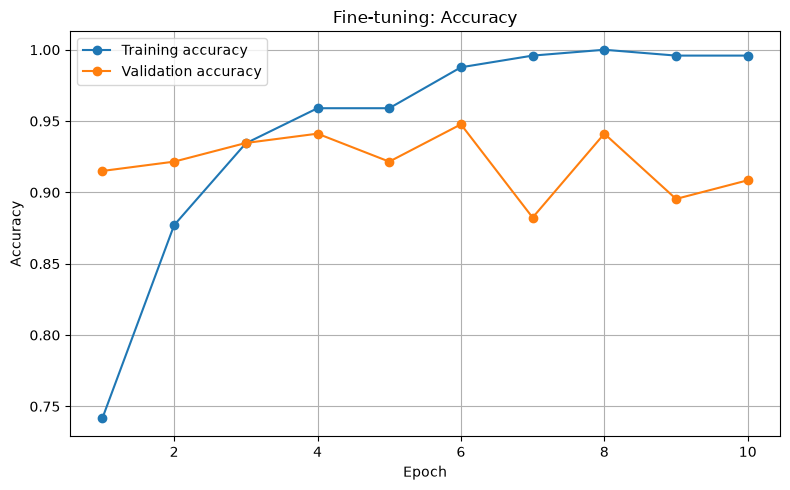

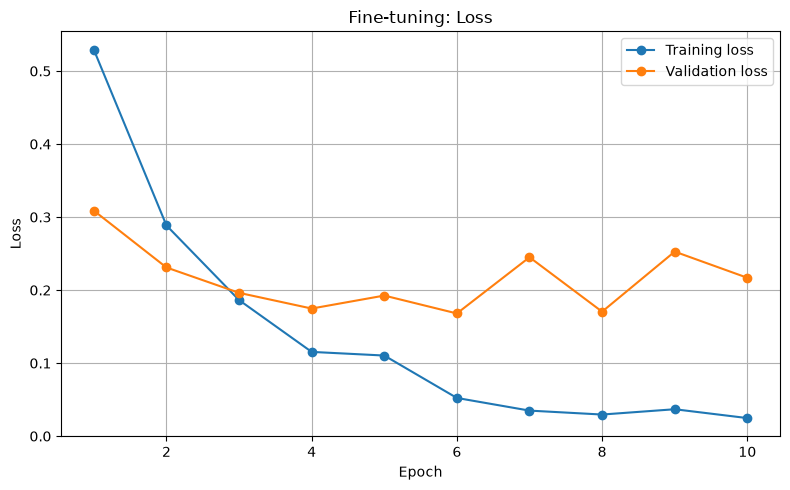

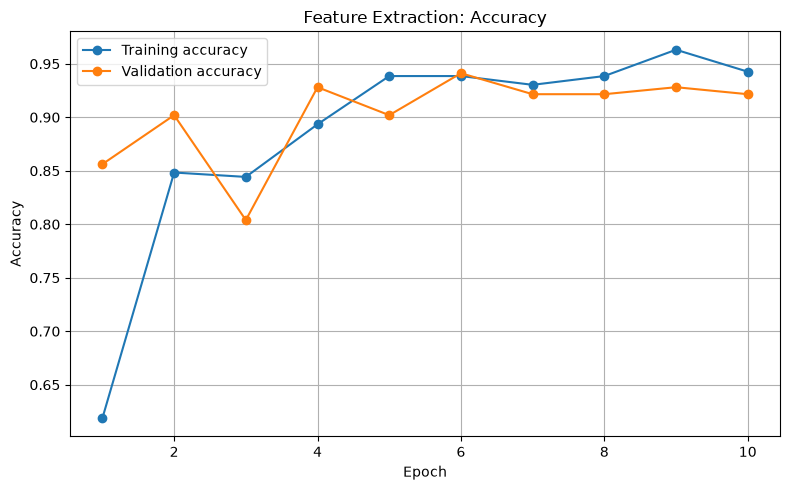

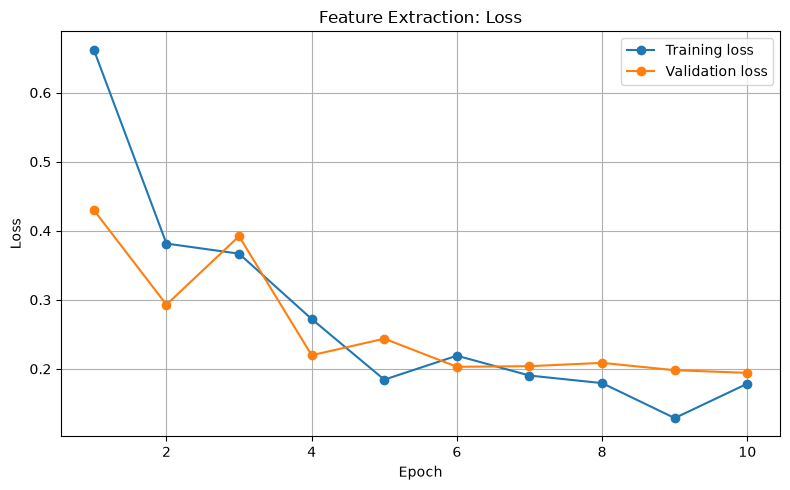

In [30]:
results_dir = "./results"
os.makedirs(results_dir, exist_ok=True)

comparison = pd.DataFrame([
    {
        "Method": "Fine-tuning",
        "Final Train Accuracy (%)":
            history_finetune["train_accuracy"][-1] * 100,
        "Best Validation Accuracy (%)":
            max(history_finetune["val_accuracy"]) * 100,
        "Final Validation Loss":
            history_finetune["val_loss"][-1]
    },
    {
        "Method": "Feature Extraction",
        "Final Train Accuracy (%)":
            history_feature["train_accuracy"][-1] * 100,
        "Best Validation Accuracy (%)":
            max(history_feature["val_accuracy"]) * 100,
        "Final Validation Loss":
            history_feature["val_loss"][-1]
    }
])

display(comparison.round(2))
comparison.to_csv(
    os.path.join(results_dir, "task3_comparison.csv"),
    index=False
)

for name, history in [
    ("Fine-tuning", history_finetune),
    ("Feature Extraction", history_feature)
]:
    epochs = range(1, len(history["train_accuracy"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_accuracy"], marker="o",
             label="Training accuracy")
    plt.plot(epochs, history["val_accuracy"], marker="o",
             label="Validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{name}: Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            results_dir,
            f"task3_{name.lower().replace(' ', '_')}_accuracy.png"
        ),
        dpi=150
    )
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_loss"], marker="o",
             label="Training loss")
    plt.plot(epochs, history["val_loss"], marker="o",
             label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{name}: Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            results_dir,
            f"task3_{name.lower().replace(' ', '_')}_loss.png"
        ),
        dpi=150
    )
    plt.show()

pd.DataFrame(history_finetune).to_csv(
    os.path.join(results_dir, "task3_finetune_history.csv"),
    index=False
)
pd.DataFrame(history_feature).to_csv(
    os.path.join(results_dir, "task3_feature_extraction_history.csv"),
    index=False
)

torch.save(
    model_finetune.state_dict(),
    os.path.join(results_dir, "task3_resnet18_finetuned.pth")
)
torch.save(
    model_feature.state_dict(),
    os.path.join(results_dir, "task3_resnet18_feature_extractor.pth")
)
